# Phase 4 · 3/3 — Prédiction du churn par Machine Learning

**VIGIE · Groupe BI 5** — Raed Meddeb · Salsabil Ben Elhadj · Salah Chebbi · Ines Ayed
Projet Intégré, ESPRIT School of Business · Tuteurs : Aymen Ben Brik et Hela Hammami

---

**Question posée.** À partir du profil d'un client, peut-on estimer sa probabilité de partir ?

| Étape | Contenu |
|---|---|
| 1 | Grain et cible |
| 2 | **Contrôle de la fuite de cible** |
| 3 | Variables retenues |
| 4 | Découpage par client, sans contamination |
| 5 | Comparaison de trois modèles |
| 6 | Optimisation des hyperparamètres |
| 7 | Analyse de sensibilité : que vaut chaque famille de variables ? |
| 8 | Calibration et courbe de gains |
| 9 | Interprétabilité : importance et valeurs SHAP |
| 10 | Modèle final, limites, export |

Le code des modèles est dans `04_machine_learning/src/churn.py` ; ce notebook l'exécute et commente les résultats.
*Aucune ligne client n'est affichée.*

In [1]:
import json
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from IPython.display import display
from sklearn.calibration import calibration_curve
from sklearn.metrics import precision_recall_curve, roc_auc_score, roc_curve

RACINE = Path.cwd().resolve().parents[1]
sys.path.insert(0, str(RACINE))
sys.path.insert(0, str(RACINE / "04_machine_learning" / "src"))
sys.path.insert(0, str(RACINE / "05_web_app"))
import churn
import export_app
from utils import preprocessing            # 05_web_app/utils : le même code que l'application
from vigie import config, donnees, style, variables

warnings.filterwarnings("ignore")
style.appliquer()
C = config.COULEURS
fr = style.milliers

df = donnees.charger()
comptes = donnees.grain_compte(df)
clients = donnees.grain_client(df, comptes)
date_ref = donnees.date_reference(df)

## 1. Grain et cible

**Grain : le client.** Une ligne = un client ayant au moins un compte.

**Cible : `CHURN = 1` si tous les comptes du client sont clos.** Elle découle de la définition du projet
(`ACCOUNT_STATUS = "Closed"`). Comme aucun client n'a à la fois un compte actif et un compte clos, cette cible
est sans ambiguïté.

**Pourquoi le client plutôt que le compte ?** Les seules variables utilisables sont des caractéristiques du
*client* (voir le contrôle de fuite ci-dessous). Au grain compte, un client à trois comptes donnerait trois lignes
identiques, avec la même cible : il pèserait trois fois sans apporter d'information. Le grain client évite ce biais.

In [2]:
profils, X, y, groupes = variables.jeu_modelisation(clients, date_ref)
repartition = pd.Series({
    "Clients dans le périmètre (au moins un compte)": len(y),
    "Clients restés (CHURN = 0)": int((y == 0).sum()),
    "Clients partis (CHURN = 1)": int((y == 1).sum()),
}, name="Effectif").to_frame()
repartition["Part"] = (repartition["Effectif"] / len(y)).map("{:.1%}".format)
display(repartition)
mixtes = int((comptes.groupby("CUSTOMER_NO")["CHURN"].nunique() > 1).sum())
print("Clients ayant à la fois un compte actif et un compte clos :", mixtes)

,Effectif,Part
Clients dans le périmètre (au moins un compte),319040,100.0%
Clients restés (CHURN = 0),201695,63.2%
Clients partis (CHURN = 1),117345,36.8%


Clients ayant à la fois un compte actif et un compte clos : 0


**Déséquilibre.** 36,8 % de clients partis : le déséquilibre est **modéré**. Nous n'appliquons **aucun
rééquilibrage** (ni sur-échantillonnage, ni pondération des classes). Deux raisons : (1) rééquilibrer déforme les
probabilités prédites, que l'application affiche telles quelles ; (2) le compromis precision / recall se règle
plus simplement, et de façon transparente, par le **seuil de décision** (section 5).

## 2. Contrôle de la fuite de cible

Le fichier est une photographie prise **après** les clôtures. Certaines colonnes ne *prédisent* pas la clôture :
elles la *constatent*. Les utiliser donnerait un modèle parfait en apparence et inutilisable en pratique, puisque
ces informations n'existent pas tant que le client n'est pas parti.

### 2.1 Test du vide : une colonne vide suffit-elle à deviner la cible ?

Pour chaque colonne, on prédit la cible avec **un seul indicateur : « la valeur est manquante »**, et on mesure
l'AUC obtenue. Une colonne saine donne 0,5 (le vide n'apprend rien).

,% vide si actif,% vide si clos,AUC du vide,Verdict
Variable,,,,
ACCT_CLOSE_DATE,100.0,0.0,1.000,FUITE — exclue
CLOSURE_REASON,100.0,9.1,0.954,FUITE — exclue
CURRENCY,0.0,67.8,0.839,FUITE — exclue
ACCOUNT_CATEGORY,0.0,67.8,0.839,FUITE — exclue
ACCT_OPENING_DATE,0.0,67.8,0.839,FUITE — exclue
ACCOUNT_TYPE_DESC,0.0,67.8,0.839,FUITE — exclue
ACCT_BALANCE,0.0,67.8,0.839,FUITE — exclue
AMOUNT,15.0,77.7,0.813,FUITE — exclue
PRODUCT_LINE,14.7,76.0,0.806,FUITE — exclue


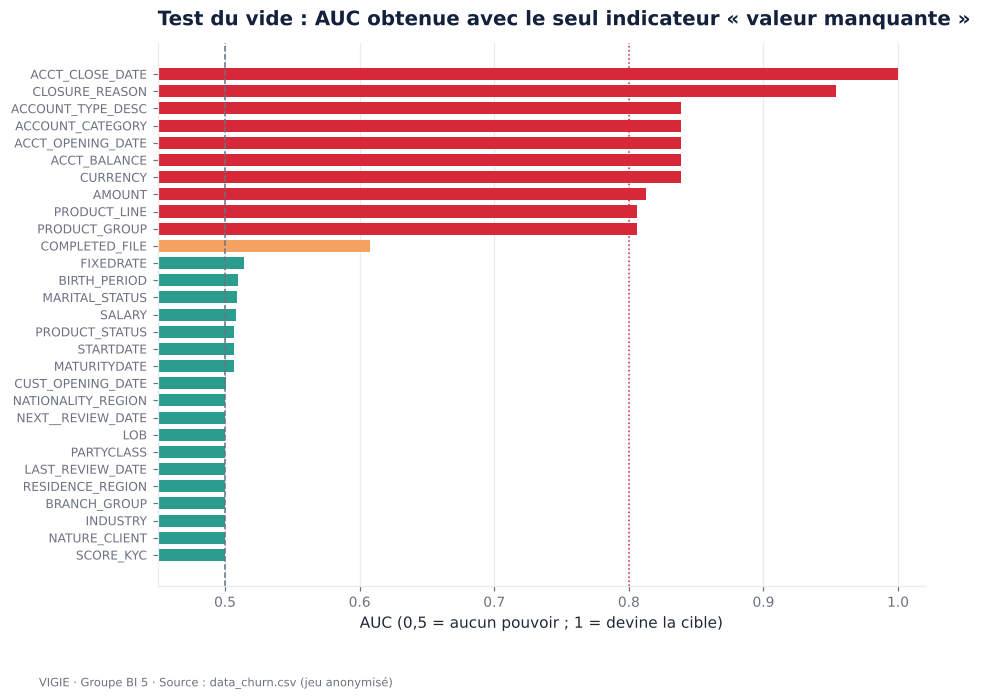

In [3]:
table_compte = comptes.merge(clients[donnees.COLONNES_CLIENT], on="CUSTOMER_NO", suffixes=("", "_CLIENT"))
colonnes_testees = [c for c in df.columns if c not in ("CUSTOMER_NO", "ACCOUNT_NO", "ACCOUNT_STATUS")]
audit = churn.audit_fuite(table_compte, "CHURN", colonnes_testees)
display(audit)

fig, ax = plt.subplots(figsize=(9, 6.4))
a = audit["AUC du vide"].sort_values()
couleurs = [C["churn"] if v >= 0.8 else C["ambre"] if v >= 0.6 else C["retention"] for v in a]
ax.barh(a.index, a, color=couleurs, height=0.7)
ax.axvline(0.5, color=C["gris"], ls="--", lw=1)
ax.axvline(0.8, color=C["churn"], ls=":", lw=1)
ax.set_xlim(0.45, 1.02)
ax.set_title("Test du vide : AUC obtenue avec le seul indicateur « valeur manquante »")
ax.set_xlabel("AUC (0,5 = aucun pouvoir ; 1 = devine la cible)")
ax.tick_params(axis="y", labelsize=8)
ax.grid(axis="y", visible=False)
style.enregistrer(fig, "04_fuite_test_du_vide")
plt.show()

### 2.2 Test des modalités : certaines valeurs désignent-elles la clôture ?

Le test du vide ne voit pas tout. `PRODUCT_STATUS` est vide aussi souvent pour les comptes actifs que pour les
comptes clos, mais certaines de ses **valeurs** décrivent la fermeture elle-même.

In [4]:
statut_produit = (comptes.groupby(comptes["PRODUCT_STATUS"].fillna("(vide)"))["CHURN"]
                  .agg(Comptes="size", Taux_de_cloture="mean").sort_values("Taux_de_cloture", ascending=False))
statut_produit = statut_produit[statut_produit["Comptes"] >= config.SEUIL_PETIT_EFFECTIF]
display(statut_produit.style.format({"Comptes": fr, "Taux_de_cloture": "{:.1%}"}))

,Comptes,Taux_de_cloture
PRODUCT_STATUS,,
CLOSE,220,99.1%
UNAUTH,1 685,86.6%
PENDING.CLOSURE,1 480,78.2%
AUTH,302,77.5%
(vide),367 453,36.5%
CURRENT,35 927,28.8%
EXPIRED,3 239,23.2%


### 2.3 Démonstration : ce que donne un modèle « avec fuite »

On ajoute volontairement au modèle deux variables construites sur les colonnes suspectes — la part des comptes du
client dont le solde est vide, et la part dont la famille de compte est vide — puis on compare.

In [5]:
fuite = comptes.assign(SOLDE_VIDE=comptes["ACCT_BALANCE"].isna(), FAMILLE_VIDE=comptes["ACCOUNT_CATEGORY"].isna(),
                       PRODUIT_VIDE=comptes["PRODUCT_GROUP"].isna())
fuite = fuite.groupby("CUSTOMER_NO")[["SOLDE_VIDE", "FAMILLE_VIDE", "PRODUIT_VIDE"]].mean()
X_fuite = X.copy()
for col in fuite.columns:
    X_fuite[f"FUITE_{col}"] = fuite[col].reindex(groupes).to_numpy()

decoupage = churn.decouper(y, groupes)
tr, va, te = decoupage["train"], decoupage["validation"], decoupage["test"]
avec_fuite = churn.xgboost().fit(X_fuite.iloc[tr], y[tr])
sans_fuite = churn.xgboost().fit(X.iloc[tr], y[tr])
demo = pd.DataFrame({
    "ROC-AUC sur le test": [roc_auc_score(y[te], avec_fuite.predict_proba(X_fuite.iloc[te])[:, 1]),
                            roc_auc_score(y[te], sans_fuite.predict_proba(X.iloc[te])[:, 1])],
}, index=["Modèle AVEC variables de fuite", "Modèle SANS variable de fuite (retenu)"])
display(demo.round(4))

,ROC-AUC sur le test
Modèle AVEC variables de fuite,0.9511
Modèle SANS variable de fuite (retenu),0.7507


**Lecture — contrôle de la fuite.**

| Verdict | Colonnes | Décision |
|---|---|---|
| **Fuite certaine** (AUC du vide ≥ 0,80) | `ACCT_CLOSE_DATE`, `CLOSURE_REASON`, `ACCT_BALANCE`, `ACCT_OPENING_DATE`, `ACCOUNT_CATEGORY`, `ACCOUNT_TYPE_DESC`, `CURRENCY`, `AMOUNT`, `PRODUCT_GROUP`, `PRODUCT_LINE` | **Exclues**, ainsi que toute variable dérivée (ancienneté du compte, diversité des produits, indicateur de solde vide…) |
| **Fuite par les valeurs** | `PRODUCT_STATUS` (`CLOSE` : 99 % de clôtures ; `UNAUTH` : 87 % ; `PENDING.CLOSURE` : 78 %) | **Exclue** |
| **Sans intérêt prédictif propre** | `STARTDATE`, `MATURITYDATE`, `FIXEDRATE` (vides à ≈ 90 %, attributs du produit) | Non retenues |
| **À surveiller** (AUC du vide 0,61) | `COMPLETED_FILE` | Conservée : c'est une caractéristique du *client*, recommandée par le guide. Son poids est mesuré à part (section 7) |
| **Saines** | toutes les autres caractéristiques du client | Conservées |

La démonstration est sans appel : il suffit d'ajouter trois indicateurs de vide pour que l'AUC passe de 0,75 à
**0,95**. **Ce n'est pas un bon modèle, c'est un modèle qui lit la réponse** : ces vides n'apparaissent qu'une fois
le compte clos. Sans eux, l'AUC est de 0,75 : c'est le vrai niveau de ce que le profil d'un client permet d'anticiper.

Le document de description avait prévenu que la famille de compte, la devise et le montant « pouvaient suivre le
même schéma » que le solde : le test du vide le **confirme**, et l'étend à la date d'ouverture du compte.

## 3. Variables retenues

Douze variables, toutes connues **avant** un éventuel départ, réparties en trois familles.

In [6]:
origine = {
    "AGE": ("BIRTH_PERIOD", "date de référence − milieu de la tranche de naissance"),
    "STATUT_MARITAL": ("MARITAL_STATUS", "vide → « NR »"),
    "ZONE_RESIDENCE": ("RESIDENCE_REGION", "modalités rares regroupées"),
    "ANCIENNETE_CLIENT": ("CUST_OPENING_DATE", "années depuis l'entrée en relation"),
    "NB_COMPTES": ("ACCOUNT_NO", "nombre de comptes distincts du client"),
    "NATURE_CLIENT": ("NATURE_CLIENT", "TRPP / TRPM → « AUTRE »"),
    "SEGMENT": ("PARTYCLASS", "—"),
    "SALAIRE": ("SALARY", "le vide est conservé (non déclaré)"),
    "SCORE_KYC": ("SCORE_KYC", "vide → « NR »"),
    "DOSSIER_COMPLET": ("COMPLETED_FILE", "YES → 1, vide → 0"),
    "MOIS_DEPUIS_REVUE": ("LAST_REVIEW_DATE", "mois écoulés depuis la dernière revue"),
    "MOIS_AVANT_PROCHAINE_REVUE": ("NEXT__REVIEW_DATE", "mois restants (négatif = revue en retard)"),
}
lignes = []
for famille, noms in variables.famille_variables().items():
    for nom in noms:
        lignes.append({"Famille": famille, "Variable": nom, "Libellé": preprocessing.LIBELLES[nom],
                       "Colonne source": origine[nom][0], "Construction": origine[nom][1],
                       "Type": "Numérique" if nom in preprocessing.NUMERIQUES else "Catégorielle",
                       "% manquant": f"{profils[nom].isna().mean():.1%}" if nom in preprocessing.NUMERIQUES else "—"})
display(pd.DataFrame(lignes).set_index(["Famille", "Variable"]))
print(f"Matrice du modèle : {X.shape[0]:,} clients × {X.shape[1]} colonnes "
      f"({len(preprocessing.NUMERIQUES)} numériques + {X.shape[1] - len(preprocessing.NUMERIQUES)} indicatrices).".replace(",", " "))

Libellé  \
Famille     Variable                                                    
Démographie AGE                                                   Âge   
            STATUT_MARITAL                             Statut marital   
            ZONE_RESIDENCE                          Zone de résidence   
Relation    ANCIENNETE_CLIENT              Ancienneté client (années)   
            NB_COMPTES                              Nombre de comptes   
            NATURE_CLIENT                            Nature du client   
            SEGMENT                                Segment commercial   
            SALAIRE                                    Revenu déclaré   
Conformité  SCORE_KYC                                       Score KYC   
            DOSSIER_COMPLET                           Dossier complet   
            MOIS_DEPUIS_REVUE           Mois depuis la dernière revue   
            MOIS_AVANT_PROCHAINE_REVUE  Mois avant la prochaine revue   

                                           Colonne source  \
Famille     Variable                                        
Démographie AGE                              BIRTH_PERIOD   
            STATUT_MARITAL                 MARITAL_STATUS   
            ZONE_RESIDENCE               RESIDENCE_REGION   
Relation    ANCIENNETE_CLIENT           CUST_OPENING_DATE   
            NB_COMPTES                         ACCOUNT_NO   
            NATURE_CLIENT                   NATURE_CLIENT   
            SEGMENT                            PARTYCLASS   
            SALAIRE                                SALARY   
Conformité  SCORE_KYC                           SCORE_KYC   
            DOSSIER_COMPLET                COMPLETED_FILE   
            MOIS_DEPUIS_REVUE            LAST_REVIEW_DATE   
            MOIS_AVANT_PROCHAINE_REVUE  NEXT__REVIEW_DATE   

                                                                             Construction  \
Famille     Variable                                                                        
Démographie AGE                         date de référence − milieu de la tranche de na...   
            STATUT_MARITAL                                                  vide → « NR »   
            ZONE_RESIDENCE                                     modalités rares regroupées   
Relation    ANCIENNETE_CLIENT                          années depuis l'entrée en relation   
            NB_COMPTES                              nombre de comptes distincts du client   
            NATURE_CLIENT                                         TRPP / TRPM → « AUTRE »   
            SEGMENT                                                                     —   
            SALAIRE                                    le vide est conservé (non déclaré)   
Conformité  SCORE_KYC                                                       vide → « NR »   
            DOSSIER_COMPLET                                             YES → 1, vide → 0   
            MOIS_DEPUIS_REVUE                       mois écoulés depuis la dernière revue   
            MOIS_AVANT_PROCHAINE_REVUE          mois restants (négatif = revue en retard)   

                                                Type % manquant  
Famille     Variable                                             
Démographie AGE                            Numérique       6.3%  
            STATUT_MARITAL              Catégorielle          —  
            ZONE_RESIDENCE              Catégorielle          —  
Relation    ANCIENNETE_CLIENT              Numérique       0.6%  
            NB_COMPTES                     Numérique       0.0%  
            NATURE_CLIENT               Catégorielle          —  
            SEGMENT                     Catégorielle          —  
            SALAIRE                        Numérique      67.3%  
Conformité  SCORE_KYC                   Catégorielle          —  
            DOSSIER_COMPLET                Numérique       0.0%  
            MOIS_DEPUIS_REVUE              Numérique       0.0%  
            MOIS_AVANT_

Matrice du modèle : 319 040 clients × 31 colonnes (7 numériques + 24 indicatrices).


In [7]:
# Les deux variables de revue sont-elles indépendantes ? On mesure l'écart entre dernière et prochaine revue.
perimetre = clients[clients["CHURN"].notna()]
cycle = ((perimetre["NEXT__REVIEW_DATE"] - perimetre["LAST_REVIEW_DATE"]).dt.days / 30.4375).round()
cycle_kyc = (pd.DataFrame({"Score KYC": perimetre["SCORE_KYC"], "cycle": cycle}).dropna()
             .groupby("Score KYC")["cycle"].agg(Clients="size", Cycle_le_plus_frequent=lambda s: int(s.mode().iloc[0]),
                                                Part_des_clients=lambda s: (s == s.mode().iloc[0]).mean()))
display(cycle_kyc.style.format({"Clients": fr, "Cycle_le_plus_frequent": "{} mois", "Part_des_clients": "{:.1%}"}))
print(cycle_kyc.round(3).to_string())

,Clients,Cycle_le_plus_frequent,Part_des_clients
Score KYC,,,
H1,17 169,24 mois,97.2%
H2,9 795,24 mois,96.8%
H3,4 099,24 mois,96.9%
LR,256 254,48 mois,98.7%
MR,31 643,36 mois,97.7%


           Clients  Cycle_le_plus_frequent  Part_des_clients
Score KYC                                                   
H1           17169                      24             0.972
H2            9795                      24             0.968
H3            4099                      24             0.969
LR          256254                      48             0.987
MR           31643                      36             0.977


**Constat utile : le cycle de revue est fixé par le score KYC** — 48 mois pour le risque faible (`LR`), 36 mois
pour le risque moyen (`MR`), 24 mois pour les risques élevés (`H1` à `H3`), et cela pour 97 à 99 % des clients.
Les deux variables de revue ne sont donc pas indépendantes : *mois avant la prochaine revue = cycle − mois depuis
la dernière revue*. Nous gardons les deux, car la seconde donne directement l'information la plus parlante — la
revue est-elle **en retard** ? — sans que le modèle ait à la reconstruire. Conséquence pour l'application : le
formulaire ne demande que la date de la dernière revue et **déduit** la prochaine, ce qui interdit de saisir un
profil incohérent.

**Variables écartées par choix** (et non pour fuite) :

* `LOB` : strictement équivalente à `PARTYCLASS` (V de Cramér = 1) ; `NATIONALITY_REGION` : très liée à la résidence.
* `INDUSTRY` et `BRANCH_GROUP` : testées en section 7, elles n'apportent presque rien ; les écarter donne un modèle
  plus simple et un formulaire plus court dans l'application.

**Un seul code d'encodage.** La transformation d'un profil en variables est faite par
`05_web_app/utils/preprocessing.py`, importé ici. L'application utilise le même fichier : ce que le modèle apprend
et ce qu'on lui présente ensuite sont construits de la même façon.

## 4. Découpage par client, sans contamination

`GroupShuffleSplit` avec `CUSTOMER_NO` comme groupe : un client est tout entier dans un seul jeu.

In [8]:
plan = pd.DataFrame({
    "Rôle": ["Apprentissage", "Choix du seuil de décision", "Évaluation finale (jamais utilisé avant)"],
    "Clients": [len(tr), len(va), len(te)],
    "Part": [f"{len(i) / len(y):.0%}" for i in (tr, va, te)],
    "Taux de churn": [f"{y[i].mean():.1%}" for i in (tr, va, te)],
}, index=["Entraînement", "Validation", "Test"])
display(plan)
communs = {f"{a} ∩ {b}": len(set(groupes[decoupage[a]]) & set(groupes[decoupage[b]]))
           for a, b in [("train", "validation"), ("train", "test"), ("validation", "test")]}
print("Clients communs entre deux jeux :", communs)

,Rôle,Clients,Part,Taux de churn
Entraînement,Apprentissage,223328,70%,36.7%
Validation,Choix du seuil de décision,47856,15%,36.9%
Test,Évaluation finale (jamais utilisé avant),47856,15%,36.9%


Clients communs entre deux jeux : {'train ∩ validation': 0, 'train ∩ test': 0, 'validation ∩ test': 0}


Aucun client n'est partagé entre deux jeux, et le taux de churn est le même dans les trois : le découpage est
propre et représentatif.

## 5. Comparaison de trois modèles

| Modèle | Principe | Intérêt |
|---|---|---|
| Référence | prédit le taux moyen pour tout le monde | plancher : tout modèle doit faire mieux |
| **Régression logistique** | somme pondérée des variables | simple, linéaire, lisible |
| **Random Forest** | moyenne de 300 arbres indépendants | capte le non-linéaire, robuste |
| **XGBoost** | arbres construits l'un après l'autre, chacun corrigeant le précédent | souvent le plus performant sur données tabulaires ; gère nativement les valeurs manquantes |

Pour la régression logistique et la forêt, les valeurs manquantes sont remplacées par la médiane (calculée sur
l'entraînement) et un indicateur « valeur manquante » est ajouté. XGBoost traite les manquants lui-même.

**Seuil de décision.** Chaque modèle fournit une probabilité. Le seuil qui transforme cette probabilité en
« à risque / pas à risque » est choisi sur le jeu de **validation** (celui qui maximise le F1), puis appliqué tel
quel au jeu de test.

In [9]:
entraines, probas, lignes = {}, {}, {}
for nom, modele in churn.modeles().items():
    modele.fit(X.iloc[tr], y[tr])
    p_va, p_te = modele.predict_proba(X.iloc[va])[:, 1], modele.predict_proba(X.iloc[te])[:, 1]
    seuil = 0.5 if nom.startswith("Référence") else churn.seuil_f1(y[va], p_va)
    entraines[nom], probas[nom], lignes[nom] = modele, p_te, churn.evaluer(y[te], p_te, seuil)
comparaison = pd.DataFrame(lignes).T
colonnes_metriques = ["ROC-AUC", "PR-AUC", "Precision", "Recall", "F1", "Accuracy", "Brier", "Seuil"]
display(comparaison[colonnes_metriques].astype(float).round(3))
print(comparaison[colonnes_metriques].astype(float).round(4).to_string())

,ROC-AUC,PR-AUC,Precision,Recall,F1,Accuracy,Brier,Seuil
Référence (taux moyen),0.500,0.369,0.000,0.000,0.000,0.631,0.233,0.500
Régression logistique,0.686,0.538,0.518,0.675,0.586,0.648,0.209,0.339
Random Forest,0.748,0.607,0.515,0.813,0.630,0.649,0.193,0.299
XGBoost,0.751,0.611,0.518,0.807,0.631,0.652,0.192,0.298


                        ROC-AUC  PR-AUC  Precision  Recall      F1  Accuracy   Brier   Seuil
Référence (taux moyen)   0.5000  0.3686     0.0000  0.0000  0.0000    0.6314  0.2327  0.5000
Régression logistique    0.6859  0.5375     0.5177  0.6755  0.5862    0.6485  0.2093  0.3388
Random Forest            0.7480  0.6070     0.5148  0.8132  0.6305    0.6486  0.1926  0.2989
XGBoost                  0.7507  0.6112     0.5182  0.8068  0.6311    0.6524  0.1916  0.2982


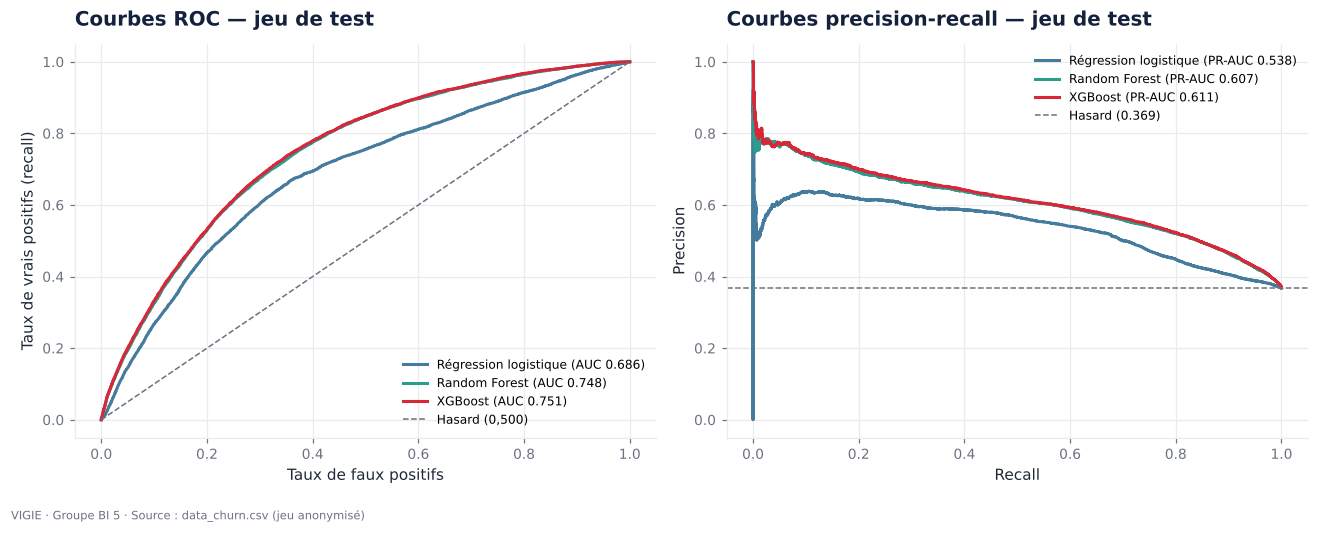

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
palette = {"Régression logistique": C["ciel"], "Random Forest": C["retention"], "XGBoost": C["churn"]}
for nom, couleur in palette.items():
    fpr, tpr, _ = roc_curve(y[te], probas[nom])
    axes[0].plot(fpr, tpr, color=couleur, lw=2, label=f"{nom} (AUC {comparaison.loc[nom, 'ROC-AUC']:.3f})")
    pr, rc, _ = precision_recall_curve(y[te], probas[nom])
    axes[1].plot(rc, pr, color=couleur, lw=2, label=f"{nom} (PR-AUC {comparaison.loc[nom, 'PR-AUC']:.3f})")
axes[0].plot([0, 1], [0, 1], color=C["gris"], ls="--", lw=1, label="Hasard (0,500)")
axes[0].set_xlabel("Taux de faux positifs")
axes[0].set_ylabel("Taux de vrais positifs (recall)")
axes[0].set_title("Courbes ROC — jeu de test")
axes[1].axhline(y[te].mean(), color=C["gris"], ls="--", lw=1, label=f"Hasard ({y[te].mean():.3f})")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Courbes precision-recall — jeu de test")
for ax in axes:
    ax.legend(loc="lower right" if ax is axes[0] else "upper right", fontsize=8)
fig.tight_layout()
style.enregistrer(fig, "04_churn_roc_pr")
plt.show()

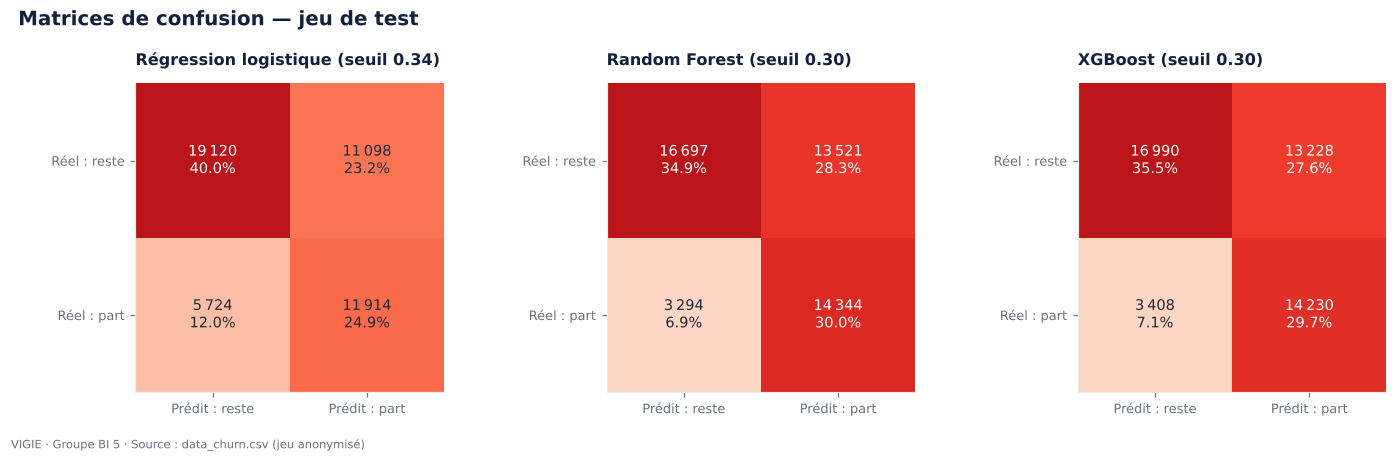

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.9))
for ax, nom in zip(axes, palette):
    r = comparaison.loc[nom]
    matrice = np.array([[r["VN"], r["FP"]], [r["FN"], r["VP"]]], dtype=float)
    ax.imshow(matrice, cmap="Reds", vmin=0, vmax=matrice.max() * 1.25)
    for (i, j), v in np.ndenumerate(matrice):
        ax.text(j, i, f"{fr(v)}\n{v / matrice.sum():.1%}", ha="center", va="center", fontsize=9.5,
                color="white" if v > matrice.max() * 0.7 else C["texte"])
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(["Prédit : reste", "Prédit : part"], fontsize=8.5)
    ax.set_yticklabels(["Réel : reste", "Réel : part"], fontsize=8.5)
    ax.set_title(f"{nom} (seuil {r['Seuil']:.2f})", fontsize=10.5)
    ax.grid(False)
fig.suptitle("Matrices de confusion — jeu de test", x=0.01, ha="left", fontweight="bold", color=C["encre"], fontsize=13)
fig.tight_layout()
style.enregistrer(fig, "04_churn_matrices_confusion")
plt.show()

**Lecture — comparaison des modèles** (jeu de test, 47 856 clients).

* **Les trois modèles battent largement la référence** : la PR-AUC passe de 0,37 (le taux de churn) à 0,54–0,61.
* **Les modèles à base d'arbres dominent la régression logistique** : +0,06 de ROC-AUC. C'était attendu depuis
  l'analyse bivariée : l'âge et l'ancienneté ont un effet « en cloche » qu'un modèle linéaire ne peut pas suivre.
* **XGBoost et Random Forest sont au coude-à-coude** (0,751 contre 0,748 de ROC-AUC) ; XGBoost est légèrement
  devant sur toutes les métriques.
* **Au seuil retenu (≈ 0,30)**, XGBoost repère **81 % des clients qui partent** (recall), avec une precision de
  52 % : un client signalé sur deux part effectivement, alors que le taux de base est de 37 %.
* **L'accuracy (65 %) est trompeuse** : la référence qui prédit « personne ne part » atteint déjà 63 %, tout en
  ne détectant aucun départ. C'est pourquoi on ne juge pas un modèle de churn sur l'accuracy.

**Pourquoi un seuil à 0,30 et non 0,50 ?** Manquer un client qui part coûte plus cher que contacter à tort un
client fidèle. Le seuil qui maximise le F1 sur la validation privilégie donc le recall. Ce seuil est un réglage
métier : il peut être déplacé selon le budget de la campagne de rétention.

## 6. Optimisation des hyperparamètres

Recherche aléatoire sur XGBoost : 12 combinaisons, évaluées par **validation croisée à 3 plis, par client**
(`GroupKFold`), sur le jeu d'entraînement uniquement. Critère : PR-AUC.

In [12]:
meilleurs, recherche = churn.optimiser_xgboost(X.iloc[tr], y[tr], groupes[tr])
apercu = recherche.head(5).copy()
apercu["params"] = apercu["params"].map(lambda p: ", ".join(f"{k}={v}" for k, v in sorted(p.items())))
apercu.columns = ["Rang", "PR-AUC moyenne (3 plis)", "Écart-type", "Hyperparamètres"]
pd.set_option("display.max_colwidth", 200)
display(apercu.round(4).set_index("Rang"))
print(f"PR-AUC de la moins bonne combinaison : {recherche['mean_test_score'].min():.4f}   |   "
      f"de la meilleure : {recherche['mean_test_score'].max():.4f}")
print("Hyperparamètres retenus :", meilleurs)

final = churn.xgboost(**meilleurs).fit(X.iloc[tr], y[tr])
p_va, p_te = final.predict_proba(X.iloc[va])[:, 1], final.predict_proba(X.iloc[te])[:, 1]
seuil_final = churn.seuil_f1(y[va], p_va)
metriques_final = churn.evaluer(y[te], p_te, seuil_final)
avant_apres = pd.DataFrame({"XGBoost par défaut": comparaison.loc["XGBoost"], "XGBoost optimisé": metriques_final}).T
display(avant_apres[colonnes_metriques].astype(float).round(4))

# Stabilité : le modèle sur-apprend-il ?
stabilite = pd.DataFrame({
    jeu: {"ROC-AUC": roc_auc_score(y[i], final.predict_proba(X.iloc[i])[:, 1])}
    for jeu, i in (("Entraînement", tr), ("Validation", va), ("Test", te))}).T
display(stabilite.round(4))

,PR-AUC moyenne (3 plis),Écart-type,Hyperparamètres
Rang,,,
1,0.6133,0.0040,"colsample_bytree=0.8, learning_rate=0.05, max_depth=7, min_child_weight=1, n_estimators=300, reg_lambda=1, subsample=0.9"
2,0.6131,0.0042,"colsample_bytree=0.6, learning_rate=0.03, max_depth=8, min_child_weight=5, n_estimators=600, reg_lambda=10, subsample=0.7"
3,0.6129,0.0041,"colsample_bytree=0.8, learning_rate=0.05, max_depth=8, min_child_weight=1, n_estimators=200, reg_lambda=10, subsample=0.9"
4,0.6127,0.0043,"colsample_bytree=0.8, learning_rate=0.05, max_depth=8, min_child_weight=20, n_estimators=300, reg_lambda=10, subsample=0.9"
5,0.6122,0.0040,"colsample_bytree=1.0, learning_rate=0.12, max_depth=6, min_child_weight=20, n_estimators=300, reg_lambda=10, subsample=1.0"


PR-AUC de la moins bonne combinaison : 0.6102   |   de la meilleure : 0.6133
Hyperparamètres retenus : {'subsample': 0.9, 'reg_lambda': 1, 'n_estimators': 300, 'min_child_weight': 1, 'max_depth': 7, 'learning_rate': 0.05, 'colsample_bytree': 0.8}


,ROC-AUC,PR-AUC,Precision,Recall,F1,Accuracy,Brier,Seuil
XGBoost par défaut,0.7507,0.6112,0.5182,0.8068,0.6311,0.6524,0.1916,0.2982
XGBoost optimisé,0.7508,0.6113,0.5264,0.7901,0.6318,0.6607,0.1915,0.3182


,ROC-AUC
Entraînement,0.7679
Validation,0.7518
Test,0.7508


**Lecture — optimisation.**

* **Le réglage change très peu le résultat.** Entre la moins bonne et la meilleure des 12 combinaisons, la PR-AUC
  ne varie que de 0,610 à 0,613 ; sur le test, le modèle optimisé fait jeu égal avec le modèle par défaut
  (ROC-AUC 0,7508 contre 0,7507). **Le plafond vient de l'information contenue dans les variables, pas du réglage.**
* Le modèle optimisé est retenu car il est très légèrement mieux calibré (Brier 0,1915) et que ses paramètres ont
  été validés par validation croisée.
* **Peu de sur-apprentissage** : ROC-AUC de 0,768 sur l'entraînement, 0,752 en validation, 0,751 en test. Les
  performances annoncées sont donc fiables sur de nouveaux clients.

## 7. Analyse de sensibilité : que vaut chaque famille de variables ?

On ré-entraîne le même XGBoost en retirant ou en ajoutant des groupes de variables. Cela répond à deux questions :
*d'où vient la performance ?* et *les variables écartées auraient-elles aidé ?*

In [13]:
fam = variables.famille_variables()
toutes = list(X.columns)
candidats = variables.candidats_ecartes(clients)            # secteur et groupe d'agences, encodés
X_large = pd.concat([X, candidats], axis=1)

scenarios = {
    "Modèle retenu (12 variables)": (X, toutes),
    "+ secteur d'activité et groupe d'agences (14 variables)": (X_large, list(X_large.columns)),
    "Sans les deux variables de revue": (X, [c for c in toutes if "REVUE" not in c]),
    "Sans la famille Conformité": (X, variables.colonnes_de(fam["Démographie"] + fam["Relation"])),
    "Conformité seule": (X, variables.colonnes_de(fam["Conformité"])),
    "Relation seule": (X, variables.colonnes_de(fam["Relation"])),
    "Démographie seule": (X, variables.colonnes_de(fam["Démographie"])),
}
lignes = {}
for nom, (matrice, cols) in scenarios.items():
    m = churn.xgboost(**meilleurs).fit(matrice.iloc[tr][cols], y[tr])
    p = m.predict_proba(matrice.iloc[te][cols])[:, 1]
    lignes[nom] = {"Colonnes": len(cols), "ROC-AUC": roc_auc_score(y[te], p),
                   "PR-AUC": churn.average_precision_score(y[te], p)}
sensibilite = pd.DataFrame(lignes).T
sensibilite["Écart de ROC-AUC"] = sensibilite["ROC-AUC"] - sensibilite.loc["Modèle retenu (12 variables)", "ROC-AUC"]
display(sensibilite.round(4))

,Colonnes,ROC-AUC,PR-AUC,Écart de ROC-AUC
Modèle retenu (12 variables),31.0,0.7508,0.6113,0.0000
+ secteur d'activité et groupe d'agences (14 variables),65.0,0.7564,0.6255,0.0055
Sans les deux variables de revue,29.0,0.7302,0.5934,-0.0207
Sans la famille Conformité,22.0,0.6603,0.5054,-0.0905
Conformité seule,9.0,0.7156,0.5727,-0.0352
Relation seule,11.0,0.6280,0.4702,-0.1228
Démographie seule,11.0,0.5812,0.4263,-0.1696


**Lecture — sensibilité.**

* **La conformité porte l'essentiel du signal.** À elle seule, elle atteint une ROC-AUC de 0,716 ; sans elle, le
  modèle tombe à 0,660. La relation commerciale seule donne 0,628 et la démographie seule 0,581.
* **Les trois familles se complètent** : ensemble (0,751), elles font mieux que la meilleure prise seule.
* **Sans les deux variables de revue**, le modèle perd 0,02 point d'AUC (0,730) : elles comptent, mais le modèle
  ne repose pas uniquement sur elles.
* **Secteur d'activité et groupe d'agences** apporteraient +0,006 de ROC-AUC et +0,014 de PR-AUC, au prix de
  34 colonnes supplémentaires. Nous choisissons de **ne pas les retenir** : les groupes d'agences sont des codes
  anonymes sans signification pour un profil saisi à la main, et le gain ne justifie pas de doubler la taille du
  modèle. C'est un arbitrage assumé entre performance et simplicité ; l'agence reste un axe d'analyse du tableau de bord.

⚠ **Réserve sur les variables de conformité.** Un dossier non revu peut précéder le départ (client délaissé) ou
le suivre (on ne revoit plus le dossier d'un client parti). Le jeu de données, qui est une photographie unique,
ne permet pas de trancher. Nous les conservons, comme le recommande le guide, en donnant ici la mesure exacte de
leur poids : **le modèle vaut 0,751 avec elles et 0,660 sans elles.** La vérité opérationnelle est entre les deux.

## 8. Calibration et courbe de gains

**Calibration.** Quand le modèle annonce 60 %, 60 % des clients concernés partent-ils vraiment ? C'est
indispensable ici, puisque l'application affiche la probabilité elle-même.

**Gains.** Si l'on ne peut contacter qu'une partie des clients, quelle part des départs touche-t-on en commençant
par les scores les plus élevés ?

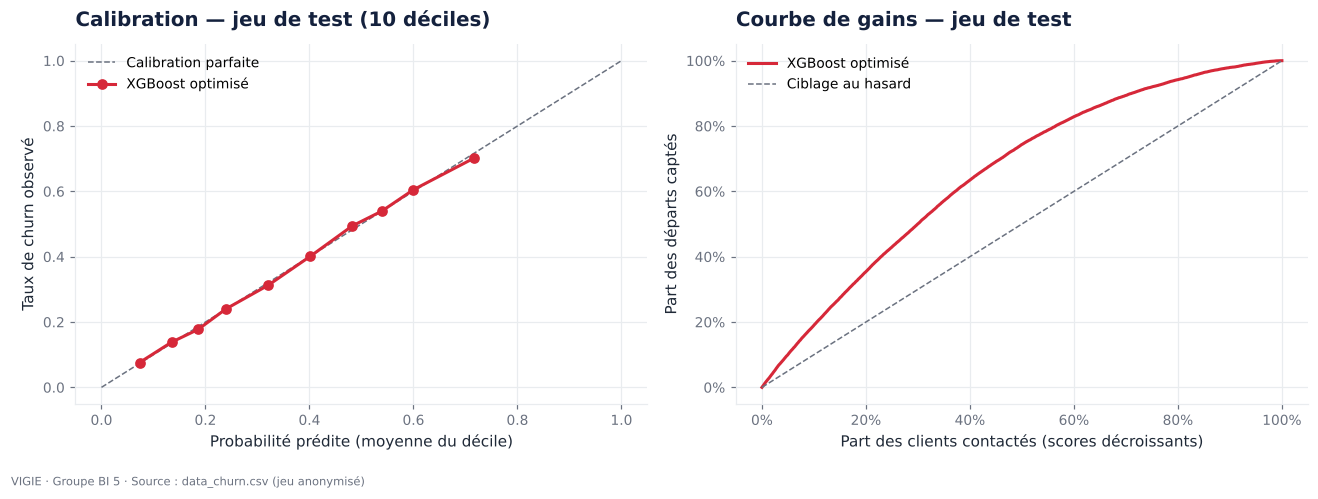

Décile de score,1,2,3,4,5,6,7,8,9,10
Probabilité prédite moyenne,0.073,0.135,0.186,0.240,0.321,0.402,0.482,0.539,0.600,0.716
Taux de churn observé,0.076,0.138,0.177,0.240,0.313,0.402,0.494,0.539,0.605,0.701
Écart,0.003,0.003,-0.008,0.001,-0.008,-0.000,0.012,0.000,0.005,-0.015


Clients ciblés,Départs captés,Taux de churn dans la cible,Lift
5%,10.0%,73.9%,2.00
10%,19.0%,70.1%,1.90
20%,35.4%,65.3%,1.77
30%,50.1%,61.5%,1.67
50%,74.4%,54.8%,1.49


   Clients ciblés  Départs captés  Taux de churn dans la cible   Lift
0            0.05           0.100                        0.739  2.005
1            0.10           0.190                        0.701  1.902
2            0.20           0.354                        0.653  1.771
3            0.30           0.501                        0.615  1.668
4            0.50           0.744                        0.548  1.487


In [14]:
fraction_reelle, proba_moyenne = calibration_curve(y[te], p_te, n_bins=10, strategy="quantile")
gains = churn.gains(y[te], p_te)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
axes[0].plot([0, 1], [0, 1], color=C["gris"], ls="--", lw=1, label="Calibration parfaite")
axes[0].plot(proba_moyenne, fraction_reelle, color=C["churn"], marker="o", lw=2, label="XGBoost optimisé")
axes[0].set_xlabel("Probabilité prédite (moyenne du décile)")
axes[0].set_ylabel("Taux de churn observé")
axes[0].set_title("Calibration — jeu de test (10 déciles)")
axes[0].legend()
ordre = np.argsort(-p_te)
cumul = np.cumsum(y[te][ordre]) / y[te].sum()
part = np.arange(1, len(ordre) + 1) / len(ordre)
axes[1].plot(part, cumul, color=C["churn"], lw=2, label="XGBoost optimisé")
axes[1].plot([0, 1], [0, 1], color=C["gris"], ls="--", lw=1, label="Ciblage au hasard")
axes[1].xaxis.set_major_formatter(style.pourcent)
axes[1].yaxis.set_major_formatter(style.pourcent)
axes[1].set_xlabel("Part des clients contactés (scores décroissants)")
axes[1].set_ylabel("Part des départs captés")
axes[1].set_title("Courbe de gains — jeu de test")
axes[1].legend()
fig.tight_layout()
style.enregistrer(fig, "04_churn_calibration_gains")
plt.show()

calibration = pd.DataFrame({"Probabilité prédite moyenne": proba_moyenne, "Taux de churn observé": fraction_reelle},
                           index=pd.RangeIndex(1, 11, name="Décile de score"))
calibration["Écart"] = calibration["Taux de churn observé"] - calibration["Probabilité prédite moyenne"]
display(calibration.round(3).T)
display(gains.style.format({"Clients ciblés": "{:.0%}", "Départs captés": "{:.1%}",
                            "Taux de churn dans la cible": "{:.1%}", "Lift": "{:.2f}"}).hide(axis="index"))
print(gains.round(3).to_string())

**Lecture — calibration.** La courbe suit la diagonale : dans chaque décile, le taux de churn observé est à moins
de 1,5 point de la probabilité annoncée. **Un score de 60 % signifie bien qu'environ 6 clients sur 10 de ce profil
sont partis.** La probabilité peut donc être affichée telle quelle dans l'application, sans recalibrage.

**Lecture — gains.** Le score permet de concentrer l'effort commercial :

* en contactant les **10 %** de clients les mieux scorés, on touche **19 %** des départs, et 70 % des clients
  contactés sont effectivement des partants ;
* avec **20 %** des clients, on touche **35 %** des départs (65 % de partants parmi les contactés, soit 1,8 fois
  mieux qu'un ciblage au hasard) ;
* avec **30 %** des clients, on touche la **moitié** des départs.

## 9. Interprétabilité

### 9.1 Importance des variables

Deux mesures complémentaires, ramenées à la variable métier (les indicatrices d'une même variable sont additionnées) :

* **Gain** (importance native de XGBoost) : part de l'amélioration du modèle due aux coupures faites sur la variable.
* **SHAP** : contribution moyenne, en valeur absolue, de la variable à la prédiction de chaque client.

,Gain (part),SHAP moyen absolu,SHAP (part)
Mois avant la prochaine revue,20.0%,0.484,34.2%
Mois depuis la dernière revue,40.0%,0.262,18.5%
Ancienneté client (années),10.0%,0.167,11.8%
Âge,11.5%,0.155,11.0%
Nombre de comptes,7.2%,0.077,5.5%
Score KYC,3.2%,0.069,4.8%
Dossier complet,0.4%,0.061,4.3%
Revenu déclaré,2.1%,0.043,3.0%
Statut marital,1.8%,0.036,2.6%
Segment commercial,1.3%,0.022,1.6%


                               Gain (part)  SHAP moyen absolu  SHAP (part)
Mois avant la prochaine revue        0.200              0.484        0.342
Mois depuis la dernière revue        0.400              0.262        0.185
Ancienneté client (années)           0.100              0.167        0.118
Âge                                  0.115              0.155        0.110
Nombre de comptes                    0.072              0.077        0.055
Score KYC                            0.032              0.069        0.048
Dossier complet                      0.004              0.061        0.043
Revenu déclaré                       0.021              0.043        0.030
Statut marital                       0.018              0.036        0.026
Segment commercial                   0.013              0.022        0.016
Nature du client                     0.010              0.022        0.015
Zone de résidence                    0.016              0.018        0.012


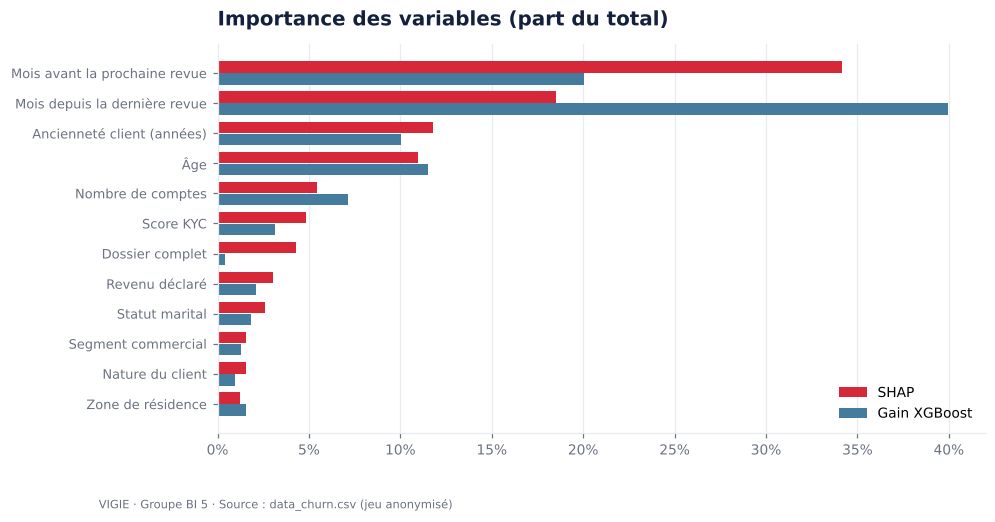

In [15]:
echantillon = np.random.default_rng(config.GRAINE).choice(te, size=5000, replace=False)
explicateur = shap.TreeExplainer(final)
valeurs_shap = explicateur.shap_values(X.iloc[echantillon])

gain = pd.Series(final.get_booster().get_score(importance_type="total_gain")).reindex(X.columns).fillna(0)
par_variable = lambda s: s.groupby([preprocessing.variable_d_origine(c) for c in s.index]).sum()  # noqa: E731
importance = pd.DataFrame({
    "Gain (part)": par_variable(gain) / gain.sum(),
    "SHAP moyen absolu": par_variable(pd.Series(np.abs(valeurs_shap).mean(axis=0), index=X.columns)),
})
importance["SHAP (part)"] = importance["SHAP moyen absolu"] / importance["SHAP moyen absolu"].sum()
importance.index = [preprocessing.LIBELLES[v] for v in importance.index]
importance = importance.sort_values("SHAP (part)", ascending=False)
display(importance.style.format({"Gain (part)": "{:.1%}", "SHAP moyen absolu": "{:.3f}", "SHAP (part)": "{:.1%}"}))
print(importance.round(3).to_string())

fig, ax = plt.subplots(figsize=(9, 4.6))
i = importance.iloc[::-1]
pos = np.arange(len(i))
ax.barh(pos + 0.2, i["SHAP (part)"], height=0.38, color=C["churn"], label="SHAP")
ax.barh(pos - 0.2, i["Gain (part)"], height=0.38, color=C["ciel"], label="Gain XGBoost")
ax.set_yticks(pos)
ax.set_yticklabels(i.index, fontsize=8.5)
ax.xaxis.set_major_formatter(style.pourcent)
ax.set_title("Importance des variables (part du total)")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
style.enregistrer(fig, "04_churn_importance")
plt.show()

**Lecture — importance.** Les deux mesures désignent les mêmes variables en tête, dans un ordre un peu différent.

* Les **deux variables de revue** pèsent à elles deux 53 % de l'importance SHAP (60 % du gain).
* Viennent ensuite l'**ancienneté** (12 %), l'**âge** (11 %) et le **nombre de comptes** (5 %).
* Les quatre variables de **conformité** représentent ensemble 62 % de l'importance SHAP.
* Segment, nature du client et zone de résidence pèsent chacune moins de 2 % : le churn ne dépend presque pas du
  segment commercial.

### 9.2 Valeurs SHAP : dans quel sens joue chaque variable ?

Chaque point est un client du jeu de test. À droite de l'axe, la variable **augmente** son risque de départ ;
à gauche, elle le **réduit**. La couleur indique si la valeur de la variable est faible (bleu) ou élevée (rouge).

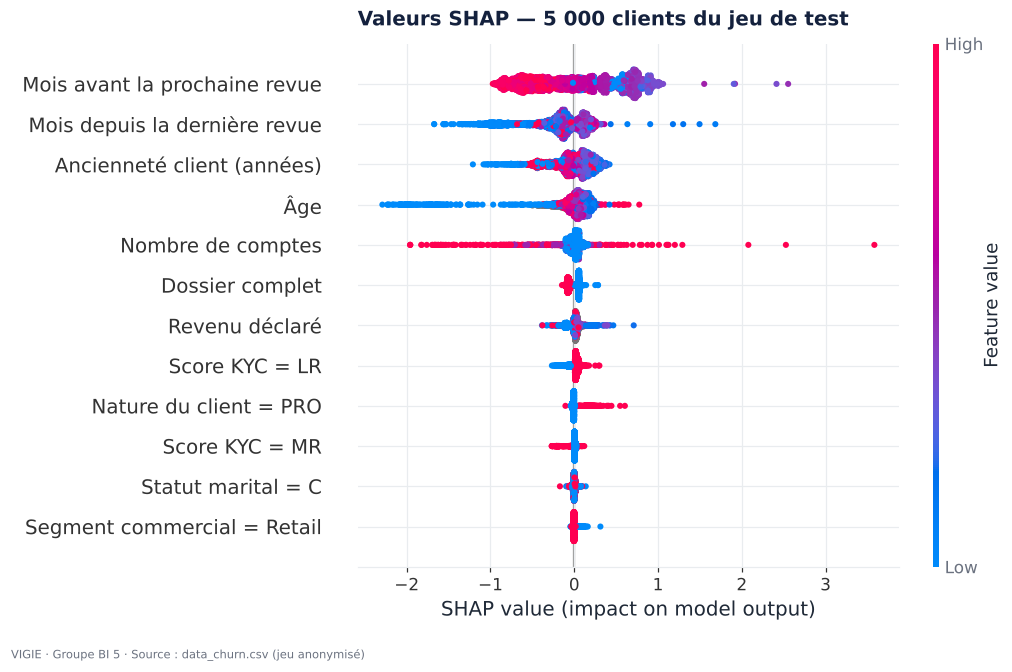

In [16]:
noms_lisibles = [c if "=" not in c else f"{preprocessing.LIBELLES[c.split('=')[0]]} = {c.split('=')[1]}" for c in X.columns]
noms_lisibles = [preprocessing.LIBELLES.get(n, n) for n in noms_lisibles]
shap.summary_plot(valeurs_shap, X.iloc[echantillon], feature_names=noms_lisibles, max_display=12, show=False,
                  plot_size=(9.5, 5.6))
fig = plt.gcf()
plt.title("Valeurs SHAP — 5 000 clients du jeu de test", loc="left", fontweight="bold", color=C["encre"])
style.enregistrer(fig, "04_churn_shap_resume")
plt.show()

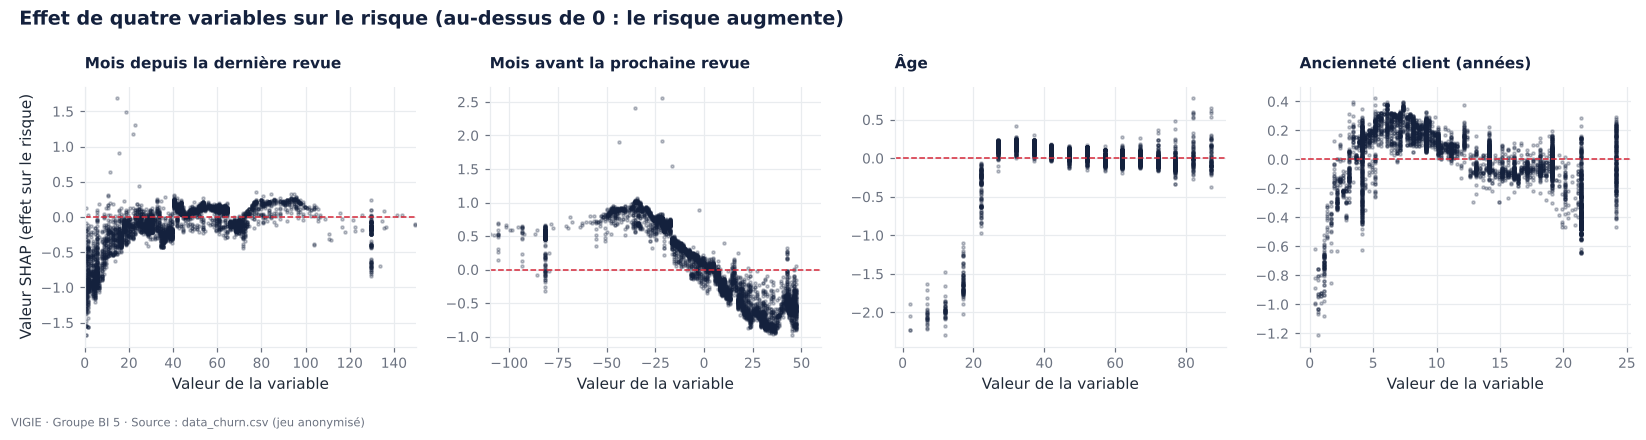

,Effet SHAP moyen (log-odds)
Revue en retard (mois avant prochaine revue < 0),0.528
Revue à venir (mois avant prochaine revue ≥ 0),-0.418
Dernière revue il y a plus de 5 ans,-0.052
Dernière revue il y a moins de 2 ans,-0.525
Moins de 25 ans,-1.134
25 à 44 ans,0.136
Ancienneté de moins de 3 ans,-0.432
Ancienneté de 5 à 10 ans,0.198
Un seul compte,0.001
Deux comptes ou plus,-0.202


In [17]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.7))
Xe = X.iloc[echantillon]
for ax, col in zip(axes, ["MOIS_DEPUIS_REVUE", "MOIS_AVANT_PROCHAINE_REVUE", "AGE", "ANCIENNETE_CLIENT"]):
    j = list(X.columns).index(col)
    ax.scatter(Xe[col], valeurs_shap[:, j], s=4, alpha=0.25, color=C["encre"])
    ax.axhline(0, color=C["churn"], lw=1, ls="--")
    ax.set_title(preprocessing.LIBELLES[col], fontsize=10)
    ax.set_xlabel("Valeur de la variable")
axes[0].set_ylabel("Valeur SHAP (effet sur le risque)")
axes[0].set_xlim(0, 150)
axes[1].set_xlim(-110, 60)
fig.suptitle("Effet de quatre variables sur le risque (au-dessus de 0 : le risque augmente)", x=0.01, ha="left",
             fontweight="bold", color=C["encre"], fontsize=12.5)
fig.tight_layout()
style.enregistrer(fig, "04_churn_shap_dependance")
plt.show()

# Quelques repères chiffrés pour la lecture des graphiques.
def effet_moyen(col, masque):
    return float(valeurs_shap[masque.to_numpy(), list(X.columns).index(col)].mean())


reperes = pd.Series({
    "Revue en retard (mois avant prochaine revue < 0)": effet_moyen("MOIS_AVANT_PROCHAINE_REVUE", Xe["MOIS_AVANT_PROCHAINE_REVUE"] < 0),
    "Revue à venir (mois avant prochaine revue ≥ 0)": effet_moyen("MOIS_AVANT_PROCHAINE_REVUE", Xe["MOIS_AVANT_PROCHAINE_REVUE"] >= 0),
    "Dernière revue il y a plus de 5 ans": effet_moyen("MOIS_DEPUIS_REVUE", Xe["MOIS_DEPUIS_REVUE"] > 60),
    "Dernière revue il y a moins de 2 ans": effet_moyen("MOIS_DEPUIS_REVUE", Xe["MOIS_DEPUIS_REVUE"] < 24),
    "Moins de 25 ans": effet_moyen("AGE", Xe["AGE"] < 25),
    "25 à 44 ans": effet_moyen("AGE", (Xe["AGE"] >= 25) & (Xe["AGE"] < 45)),
    "Ancienneté de moins de 3 ans": effet_moyen("ANCIENNETE_CLIENT", Xe["ANCIENNETE_CLIENT"] < 3),
    "Ancienneté de 5 à 10 ans": effet_moyen("ANCIENNETE_CLIENT", (Xe["ANCIENNETE_CLIENT"] >= 5) & (Xe["ANCIENNETE_CLIENT"] < 10)),
    "Un seul compte": effet_moyen("NB_COMPTES", Xe["NB_COMPTES"] == 1),
    "Deux comptes ou plus": effet_moyen("NB_COMPTES", Xe["NB_COMPTES"] >= 2),
    "Dossier complet": effet_moyen("DOSSIER_COMPLET", Xe["DOSSIER_COMPLET"] == 1),
    "Dossier incomplet": effet_moyen("DOSSIER_COMPLET", Xe["DOSSIER_COMPLET"] == 0),
}, name="Effet SHAP moyen (log-odds)")
display(reperes.round(3).to_frame())

**Lecture — le sens des effets** (valeurs SHAP moyennes ; positif = le risque augmente).

| Facteur | Effet | Lecture métier |
|---|---:|---|
| Prochaine revue **en retard** | **+0,53** | le premier signal d'alerte : un dossier qui n'est plus suivi |
| Prochaine revue à venir | −0,42 | un client dont le suivi est à jour est nettement moins à risque |
| Dernière revue il y a moins de 2 ans | −0,53 | une revue récente protège |
| Dernière revue il y a plus de 5 ans | −0,05 | effet propre faible : l'information est déjà portée par le retard de la prochaine revue |
| Moins de 25 ans | −1,13 | les plus jeunes partent très peu |
| 25 à 44 ans | +0,14 | la tranche la plus mobile |
| Ancienneté de moins de 3 ans | −0,43 | relation récente (et pas encore le temps de partir) |
| Ancienneté de 5 à 10 ans | +0,20 | la zone de fragilité de la relation |
| Deux comptes ou plus | −0,20 | en moyenne, le multi-équipement fidélise (l'effet varie selon le profil) |
| Dossier incomplet / complet | +0,05 / −0,07 | effet propre modeste une fois les revues prises en compte |

Les graphiques de dépendance confirment les formes vues en analyse bivariée : effet **en cloche** de l'âge et de
l'ancienneté, et **marche nette à zéro** pour le délai avant la prochaine revue (dès que la revue est en retard,
le risque bascule).

## 10. Modèle final, export et limites

### 10.1 Du score au niveau de risque

Pour l'application, le score est traduit en trois niveaux, dont on vérifie ici le contenu réel sur le jeu de test.

In [18]:
# Table de correspondance score → taux observé (sur le test), affichée dans l'application
bandes = pd.cut(p_te, bins=[0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 1.0], include_lowest=True)
table_score = pd.DataFrame({"y": y[te], "bande": bandes}).groupby("bande", observed=True)["y"].agg(["size", "mean"])
table_score.columns = ["Clients du test", "Taux de churn observé"]
display(table_score.style.format({"Clients du test": fr, "Taux de churn observé": "{:.1%}"}))

niveaux = pd.cut(p_te, bins=[0, 0.25, 0.50, 1.0], labels=["Faible (< 25 %)", "Modéré (25–50 %)", "Élevé (≥ 50 %)"],
                 include_lowest=True, right=False)
table_niveaux = pd.DataFrame({"y": y[te], "niveau": niveaux}).groupby("niveau", observed=True)["y"].agg(["size", "mean"])
table_niveaux["part"] = table_niveaux["size"] / table_niveaux["size"].sum()
table_niveaux.columns = ["Clients du test", "Taux de churn observé", "Part des clients"]
display(table_niveaux.style.format({"Clients du test": fr, "Taux de churn observé": "{:.1%}", "Part des clients": "{:.1%}"}))
print(table_niveaux.round(3).to_string())

,Clients du test,Taux de churn observé
bande,,
"(-0.001, 0.1]",3 871,7.3%
"(0.1, 0.2]",9 422,14.6%
"(0.2, 0.3]",7 176,24.5%
"(0.3, 0.4]",5 956,35.0%
"(0.4, 0.5]",5 929,45.7%
"(0.5, 0.6]",8 383,55.3%
"(0.6, 0.7]",4 410,63.4%
"(0.7, 0.8]",2 550,73.3%
"(0.8, 1.0]",159,81.1%


,Clients du test,Taux de churn observé,Part des clients
niveau,,,
Faible (< 25 %),17 707,15.0%,37.0%
Modéré (25–50 %),14 647,37.9%,30.6%
Élevé (≥ 50 %),15 502,60.9%,32.4%


                  Clients du test  Taux de churn observé  Part des clients
niveau                                                                    
Faible (< 25 %)             17707                  0.150             0.370
Modéré (25–50 %)            14647                  0.379             0.306
Élevé (≥ 50 %)              15502                  0.609             0.324


Les trois niveaux sont bien séparés : **15 %** de départs observés dans le niveau faible, **38 %** dans le niveau
modéré, **61 %** dans le niveau élevé. Chaque niveau regroupe environ un tiers des clients.

### 10.2 Modèle retenu : XGBoost optimisé

| Critère | Régression logistique | Random Forest | **XGBoost** |
|---|---|---|---|
| ROC-AUC / PR-AUC | 0,686 / 0,538 | 0,748 / 0,607 | **0,751 / 0,611** |
| Calibration (Brier, plus bas = mieux) | 0,209 | 0,193 | **0,192** |
| Valeurs manquantes | imputation nécessaire | imputation nécessaire | **gérées nativement** |
| Export sans données | coefficients | fichier `.pkl` volumineux | **arbres en JSON lisible (3 Mo)** |
| Explication d'une prédiction | coefficients | approchée | **SHAP exact, immédiat** |

XGBoost est retenu : il est le plus performant, le mieux calibré, et c'est le seul des deux modèles d'arbres qui
s'exporte dans un format texte **sans aucune observation**, ce qui permet de le déployer en respectant la règle
« aucune donnée dans le dépôt ».

### 10.3 Limites

1. **Performance modérée (ROC-AUC 0,75).** Le profil d'un client explique une partie du churn, pas tout. Il manque
   les données de *comportement* (mouvements, réclamations, contacts) qui annoncent habituellement un départ.
2. **Une photographie, pas un film.** Les variables sont observées à la date de référence, parfois après la
   clôture. Pour les variables de conformité, on ne peut pas exclure qu'elles reflètent en partie le départ.
3. **Clients récents.** Leur faible taux de churn tient aussi au fait qu'ils n'ont pas encore eu le temps de partir.
4. **Opérations de masse.** La moitié des clôtures vient de cinq opérations par lots : une partie des « départs »
   appris par le modèle est une décision de gestion, pas un choix du client.
5. **Usage.** Le score sert à **prioriser** une action de rétention, pas à décider seul du sort d'un client.

In [19]:
# Sauvegardes
config.MODELES.mkdir(parents=True, exist_ok=True)
import joblib
joblib.dump({"modele": final, "colonnes": list(X.columns), "seuil": seuil_final},
            config.MODELES / "model_final.pkl")                         # hors dépôt (.gitignore)

final.get_booster().save_model(config.ARTEFACTS_APP / "modele_churn.json")   # arbres uniquement, lisible
tous_les_modeles = {**comparaison.to_dict(orient="index"), "XGBoost optimisé (retenu)": metriques_final}
meta = {
    "modele": "XGBoost (gradient boosting d'arbres de décision)",
    "grain": "client", "cible": "tous les comptes du client sont clos",
    "date_reference": str(date_ref.date()),
    "source_sha256": donnees.empreinte()["sha256"],
    "entrainement": {"clients_train": int(len(tr)), "clients_validation": int(len(va)), "clients_test": int(len(te)),
                     "decoupage": "GroupShuffleSplit par CUSTOMER_NO (70 / 15 / 15)", "graine": config.GRAINE,
                     "hyperparametres": {k: (int(v) if isinstance(v, (int, np.integer)) else float(v)) for k, v in meilleurs.items()}},
    "colonnes": list(X.columns),
    "taux_de_base": round(float(y[tr].mean()), 4),
    "valeur_de_base_shap": round(float(np.ravel(explicateur.expected_value)[0]), 5),
    "seuil_alerte": round(float(seuil_final), 4),
    "metriques_test": {k: (round(float(v), 4) if k not in ("VP", "FP", "FN", "VN") else int(v)) for k, v in metriques_final.items()},
    "comparaison_modeles": {nom: {k: round(float(v), 4) for k, v in ligne.items() if k in colonnes_metriques}
                            for nom, ligne in tous_les_modeles.items()},
    "importance": {var: round(float(v), 4) for var, v in importance["SHAP (part)"].items()},
    "niveaux_de_risque": [{"niveau": str(n), "clients_test": int(r["Clients du test"]),
                           "taux_observe": round(float(r["Taux de churn observé"]), 4)} for n, r in table_niveaux.iterrows()],
    "score_vers_taux_observe": [{"de": round(float(b.left), 2) if b.left > 0 else 0.0, "a": round(float(b.right), 2),
                                 "clients_test": int(r["Clients du test"]), "taux_observe": round(float(r["Taux de churn observé"]), 4)}
                                for b, r in table_score.iterrows()],
    "gains": gains.round(4).to_dict(orient="records"),
    "marginales": export_app.marginales(profils, preprocessing.NUMERIQUES, preprocessing.CATEGORIELLES),
}
export_app.ecrire("modele_churn_meta.json", meta)
export_app.ecrire("kpi_synthese.json", export_app.agregats_synthese(df, comptes, clients, donnees.charger_referentiels()))

resultats = {
    "source_sha256": meta["source_sha256"],
    "comparaison_modeles": meta["comparaison_modeles"],
    "matrices_confusion": {nom: {k: int(ligne[k]) for k in ("VP", "FP", "FN", "VN")}
                           for nom, ligne in tous_les_modeles.items()},
    "hyperparametres": meta["entrainement"]["hyperparametres"],
    "stabilite_roc_auc": stabilite["ROC-AUC"].round(4).to_dict(),
    "sensibilite": sensibilite.round(4).to_dict(orient="index"),
    "demonstration_fuite": demo["ROC-AUC sur le test"].round(4).to_dict(),
    "audit_fuite": audit.reset_index().to_dict(orient="records"),
    "importance": importance.round(4).reset_index(names="Variable").to_dict(orient="records"),
    "gains": meta["gains"], "niveaux_de_risque": meta["niveaux_de_risque"],
}
(config.RESULTATS_ML / "churn_ml.json").write_text(json.dumps(resultats, ensure_ascii=False, indent=1), encoding="utf-8")
taille = (config.ARTEFACTS_APP / "modele_churn.json").stat().st_size / 1e6
print(f"Modèle complet  : 04_machine_learning/models/model_final.pkl (hors dépôt)")
print(f"Arbres (JSON)   : 05_web_app/artifacts/modele_churn.json ({taille:.1f} Mo, aucune observation)")
print(f"Métadonnées     : 05_web_app/artifacts/modele_churn_meta.json")
print(f"Agrégats        : 05_web_app/artifacts/kpi_synthese.json")
print(f"Résultats       : 04_machine_learning/resultats/churn_ml.json")

Modèle complet  : 04_machine_learning/models/model_final.pkl (hors dépôt)
Arbres (JSON)   : 05_web_app/artifacts/modele_churn.json (3.0 Mo, aucune observation)
Métadonnées     : 05_web_app/artifacts/modele_churn_meta.json
Agrégats        : 05_web_app/artifacts/kpi_synthese.json
Résultats       : 04_machine_learning/resultats/churn_ml.json
